# Prova 1: Simulazione Monte Carlo

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import curve_fit

# Stile comune del corso.
ROSSO = "#C92512"
GRIGIO = "#5A5A5A"
AZZURRO = "#2E6F9E"
ORO = "#D79B00"
plt.rcParams.update({
    "figure.figsize": (8.2, 4.6),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "font.size": 11,
    "legend.frameon": False,
})

## Attività 1: costruzione del modello

Non negative function!
Simmetric function!
Funzione finita: True
mu(0) compatibile con Io + B: True


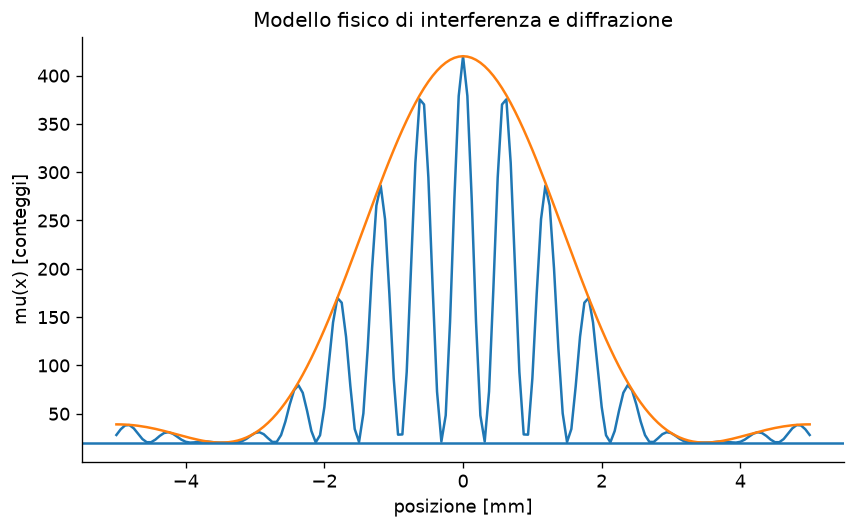

In [2]:
points = np.array(np.linspace(-5, +5, 161))
B=20 #fondo uniforme
Io=400 #scala del segnale
alpha=0.9 #larghezza inviluppo
delta=5.2 #frequenza spaziale del range
def E(x):
    return pow(np.sinc(alpha*x/np.pi), 2)

def C(x):
    return pow(np.cos(delta*x), 2)

def mu(x): #numero medio di conteggi atteso nel punto x
    return B + Io*E(x)*C(x)

positive = 0
symmetric=0
for i in range(161):
    if(mu(points[i])<0): positive += 1
    if(mu(points[i])!=mu(points[-1-i])): symmetric +=1

if(positive!=0): #controllo funzione positiva
    print("Negative function!")
else: 
    print("Non negative function!")

if(symmetric!=0): #controllo funzione è simmetrica 
    print("Non simmetric function!")
else: 
    print("Simmetric function!")

print("Funzione finita:", np.all(np.isfinite(mu(points)))) #controllo funzione finita
print("mu(0) compatibile con Io + B:", np.isclose(mu(0), Io + B)) #controllo compatibilità


    
plt.plot(points, mu(points))
plt.plot(points, B+Io*E(points))
plt.axhline(B)
plt.xlabel('posizione [mm]')
plt.ylabel('mu(x) [conteggi]')
plt.title('Modello fisico di interferenza e diffrazione')
plt.show()




Attività 2: 

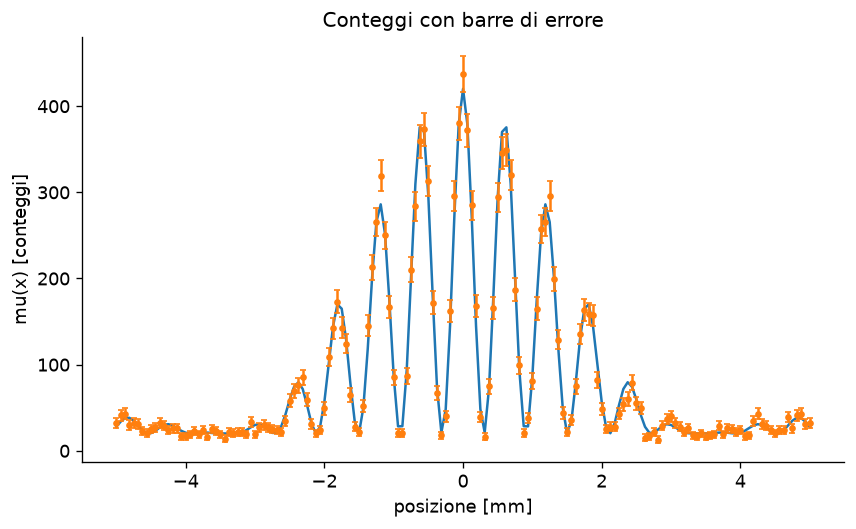

-79.45239534267876
85.81056109444035


In [3]:


rng= np.random.default_rng(seed=42)
n= np.array(rng.poisson(mu(points)))
error= np.maximum(np.sqrt(n),1.0)

plt.plot(points, mu(points))
plt.errorbar(points, n, yerr=error, fmt='o', markersize=3, capsize=2)
plt.xlabel('posizione [mm]')
plt.ylabel('mu(x) [conteggi]')
plt.title('Conteggi con barre di errore')
plt.show()


Nc=sum(n[62:100])
muc=sum(mu(points[62:100]))

print(Nc-muc)
print(np.sqrt(muc))



Attività 3

87.93324258536003
85.81056109444035


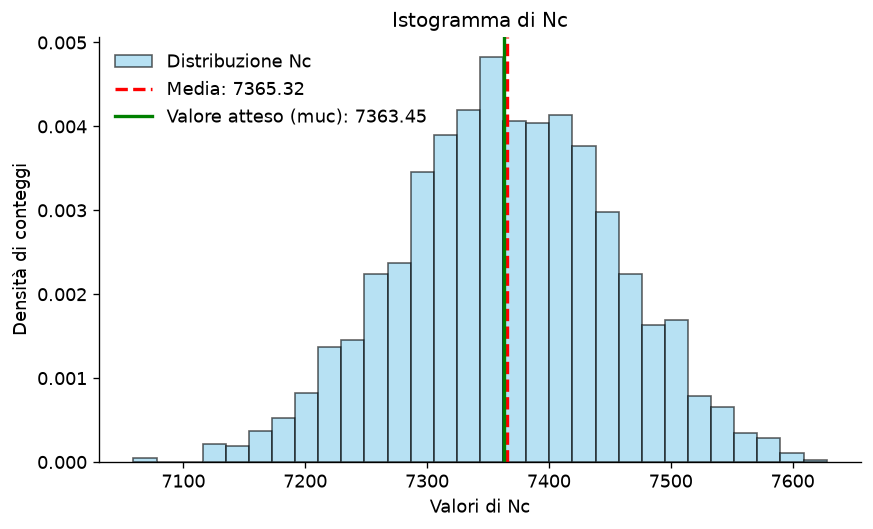

In [4]:

rng = np.random.default_rng()
Nc_arr = np.zeros(2000)  
for i in range(2000):
    Nc_arr[i] = sum(rng.poisson(mu(points[62:100])))

mean= sum(Nc_arr)/2000
dev_std= np.sqrt(sum(pow(Nc_arr-mean,2)/1999))
mean_err = dev_std/np.sqrt(2000)
scarto = (mean - muc)/muc

print(dev_std)
print(np.sqrt(muc))


plt.hist(Nc_arr, bins=30, density=True, alpha=0.6, color='skyblue', edgecolor='black', label='Distribuzione Nc')
plt.axvline(mean, color='red', linestyle='dashed', linewidth=2, label=f'Media: {mean:.2f}')
plt.axvline(muc, color='green', linestyle='solid', linewidth=2, label=f'Valore atteso (muc): {muc:.2f}')
plt.xlabel('Valori di Nc')
plt.ylabel('Densità di conteggi')
plt.title('Istogramma di Nc')
plt.legend()
plt.show() 
    


# Prova 2: fit e diagnostica

stampa parametri attività 1 su un file e inizia qui leggendoli dal file di testo

### Attività 1

Tutti i controlli sono stati passati


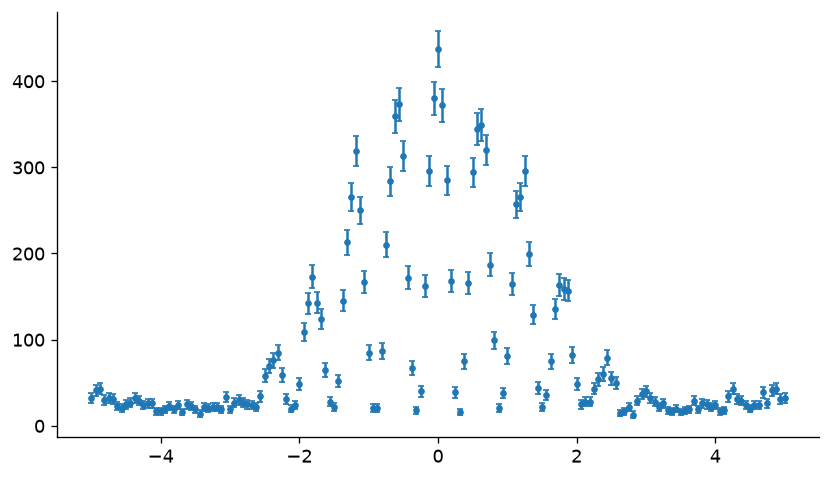

In [5]:
matrice_dati=np.column_stack((points, n, np.sqrt(n)))
np.savetxt('data.txt', matrice_dati, delimiter='\t', header='x\ty\tsigma_y')
dati=np.genfromtxt("data.txt", delimiter='\t', names=True)
x=dati["x"]
y=dati["y"]
sigma_y=dati["sigma_y"]

def verifica (x,y,sigma_y) :
    if not (len(x)==len(y)==len(sigma_y)):
        raise ValueError("Array di lunghezze diverse")
    if not (np.all(np.isfinite(x)) and np.all(np.isfinite(y)) and np.all(np.isfinite(sigma_y))):
            raise ValueError("Array con valori non finiti")
    if not np.all(sigma_y>0):
            raise ValueError("Gli errori sono negativi")
    if not np.all(np.diff(x)>0):
            raise ValueError("Posizioni non ordinate")
    print("Tutti i controlli sono stati passati")
    return True

verifica(x,y,sigma_y)

fondo= np.min(y)
massimo= np.max(y)



plt.errorbar(x,y,yerr=sigma_y,fmt='o', markersize=3, capsize=2)
plt.show()

### Attività 2:

In [6]:
B_teo= np.median(y)
I_teo = np.max(y) - B_teo
alfa = np.pi/np.min(y)
delta = np.pi/0.57
p0 = np.array([B_teo, I_teo, alfa, delta ])
lower = [0.0,0.0,0.10,1.0] #B>0, I>0, alfa>0.1 , delta>1.0 
upper=[np.inf,np.inf, 3.0,12.0] # B e I posono tendere a infinito, alfa<3.0, delta<12.0







### Attività 3:

risultati del fit
B    : 18.9614 ± 0.5002 [conteggi]
I0   : 402.5749 ± 5.0673 [conteggi]
alpha: 0.9123 ± 0.0069 [1/mm]
delta: 5.1924 ± 0.0058 [1/mm]

 controllo bounds
B    : ok
I0   : ok
alpha: ok
delta: ok
La coppia maggiormente correlata è: I0 e alpha (rho = 0.436)


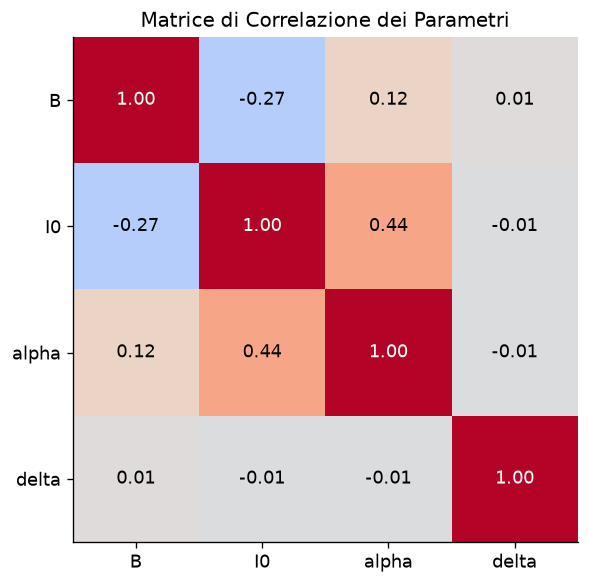

In [14]:
def modello (x, B_teo, I_teo, alfa, delta):
    E= np.sinc(alfa*x/np.pi)**2
    C= np.cos(delta*x)**2
    return B_teo+ I_teo*E*C

popt, pcov = curve_fit(
modello, x, y,
p0=p0,
sigma=sigma_y,
absolute_sigma=True,
bounds=(lower, upper),
maxfev=100000
)


incertezze = np.sqrt(np.diag(pcov))

nomi_parametri = ['B', 'I0', 'alpha', 'delta']
unita = ['[conteggi]', '[conteggi]', '[1/mm]', '[1/mm]'] 

print("risultati del fit")
for i in range(len(nomi_parametri)):
    print(f"{nomi_parametri[i]:<5}: {popt[i]:.4f} ± {incertezze[i]:.4f} {unita[i]}")

print("\n controllo bounds")
for i in range(len(nomi_parametri)):
    distanza_lower = popt[i] - lower[i]
    distanza_upper = upper[i] - popt[i]
    if distanza_lower < 1e-4 or distanza_upper < 1e-4:
        print(f"{nomi_parametri[i]} è vicino a un bound!")
    else:
        print(f"{nomi_parametri[i]:<5}: ok")

corr_matrix = np.zeros_like(pcov)

for i in range(len(popt)):
    for j in range(len(popt)):
        corr_matrix[i, j] = pcov[i, j] / (incertezze[i] * incertezze[j])

corr_matrix_no_diag = np.copy(corr_matrix)
np.fill_diagonal(corr_matrix_no_diag, 0)
idx_max = np.unravel_index(np.argmax(np.abs(corr_matrix_no_diag)), corr_matrix.shape)

param1 = nomi_parametri[idx_max[0]]
param2 = nomi_parametri[idx_max[1]]
corr_max = corr_matrix_no_diag[idx_max]

print(f"La coppia maggiormente correlata è: {param1} e {param2} (rho = {corr_max:.3f})")

plt.figure(figsize=(6, 5))
im = plt.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)

plt.xticks(ticks=np.arange(4), labels=nomi_parametri)
plt.yticks(ticks=np.arange(4), labels=nomi_parametri)
plt.title('Matrice di Correlazione dei Parametri')

for i in range(4):
    for j in range(4):
        plt.text(j, i, f"{corr_matrix[i, j]:.2f}", 
                 ha='center', va='center', 
                 color='black' if abs(corr_matrix[i, j]) < 0.6 else 'white')

plt.tight_layout()
plt.show()

### Attività 4

Chi quadro: 170.24
Gradi di libertà: 157
Chi quadrato ridotto: 1.084
P-value: 2.222e-01


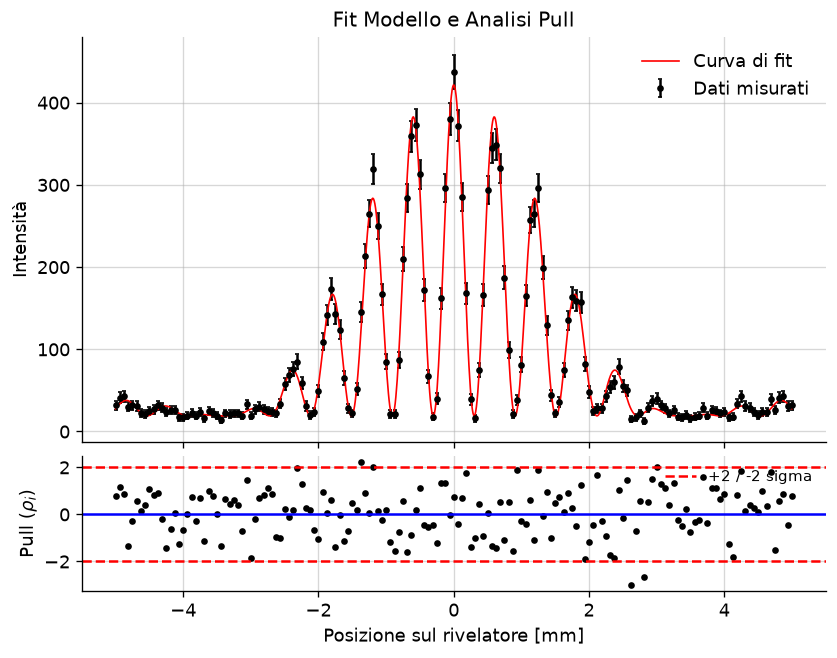

In [25]:
from scipy.stats import chi2

y_fit = modello(x, *popt)
residui = y - y_fit
pulls = residui / sigma_y
chi2_obs = np.sum(pulls**2)
N = len(x)
ndf = N - 4
chi2_rid = chi2_obs / ndf
p_value = chi2.sf(chi2_obs, ndf)

print(f"Chi quadro: {chi2_obs:.2f}")
print(f"Gradi di libertà: {ndf}")
print(f"Chi quadrato ridotto: {chi2_rid:.3f}")
print(f"P-value: {p_value:.3e}")

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, gridspec_kw={'height_ratios': [3, 1]}, figsize=(8, 6))
ax1.errorbar(x, y, yerr=sigma_y, fmt='.', color='black', label='Dati misurati', capsize=1)

x_denso = np.linspace(np.min(x), np.max(x), 1000)
y_denso = modello(x_denso, *popt)
ax1.plot(x_denso, y_denso, 'r-', lw=1, label='Curva di fit', zorder=2)

ax1.set_ylabel('Intensità')
ax1.set_title('Fit Modello e Analisi Pull')
ax1.legend()
ax1.grid(True, alpha=0.5)

ax2.plot(x, pulls, 'ko', markersize=3)

ax2.axhline(0, color='blue', linestyle='-')
ax2.axhline(2, color='red', linestyle='--', label='+2 / -2 sigma')
ax2.axhline(-2, color='red', linestyle='--')

ax2.set_xlabel('Posizione sul rivelatore [mm]')
ax2.set_ylabel('Pull ($\\rho_i$)')
ax2.legend(loc='upper right', fontsize='small')
ax2.grid(True, alpha=0.5)

plt.subplots_adjust(hspace=0.05)
plt.show()